<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 1.28k/1.28k [00:00<00:00, 974kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/saurabh00007/iriscsv/versions/1
Contents of directory /root/.cache/kagglehub/datasets/saurabh00007/iriscsv/versions/1:
- Iris.csv
Found CSV file at: /root/.cache/kagglehub/datasets/saurabh00007/iriscsv/versions/1/Iris.csv
Original Columns in downloaded Iris dataset: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Dropped 'Id' column.
Renamed Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
First 5 rows of Iris dataset:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



--- Performing K-Nearest Neighbors (KNN) with k=5 ---
KNN Confusion Matrix (k=5):
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
KNN Accuracy: 1.00


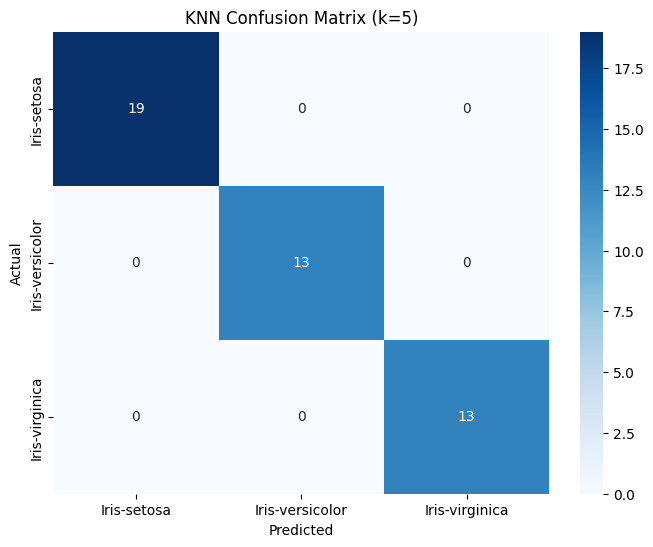


--- Performing Linear Regression ---


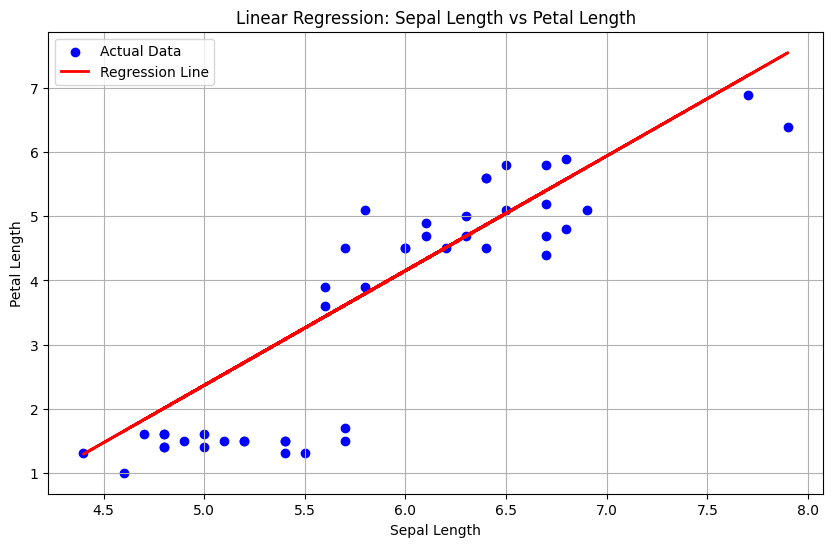

Note: Linear Regression predicts continuous values, so a standard classification confusion matrix is not directly applicable. The 'linear graph' shows the regression line.

--- Performing Logistic Regression ---
Logistic Regression Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Logistic Regression Accuracy: 1.00


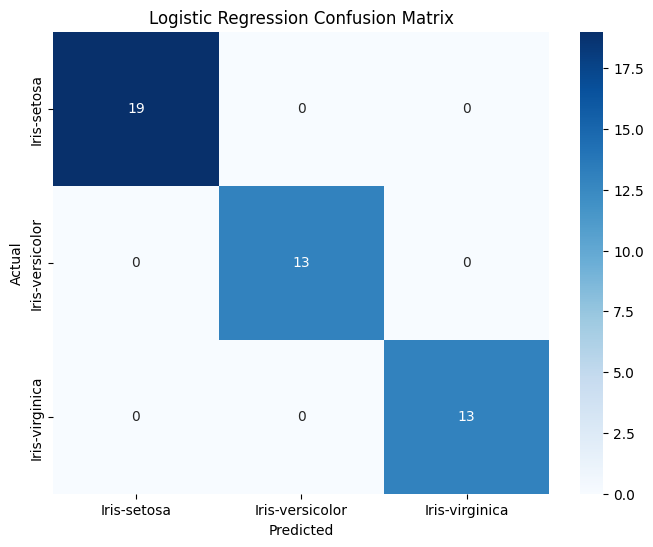

In [ ]:
import kagglehub
import pandas as pd
import os
import glob
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns


# Download the specified Kaggle dataset
try:
    path = kagglehub.dataset_download('saurabh00007/iriscsv')
    print("Path to dataset files:", path)

    # List contents of the downloaded path to identify the correct CSV file path
    print(f"Contents of directory {path}:")
    for item in os.listdir(path):
        print(f"- {item}")

    # Locate the CSV file within the downloaded path
    csv_files = glob.glob(os.path.join(path, '**', '*.csv'), recursive=True)

    df_iris = pd.DataFrame() # Initialize empty DataFrame
    if csv_files:
        csv_file = csv_files[0] # Assuming the first CSV found is the intended one
        print(f"Found CSV file at: {csv_file}")
        df_iris = pd.read_csv(csv_file)
        print("Original Columns in downloaded Iris dataset:", df_iris.columns.tolist())

        # Drop the 'Id' column if it exists
        if 'Id' in df_iris.columns:
            df_iris = df_iris.drop(columns=['Id'])
            print("Dropped 'Id' column.")

        # Rename columns for easier access and consistency
        df_iris.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

        print("Renamed Columns:", df_iris.columns.tolist())
        print("First 5 rows of Iris dataset:")
        display(df_iris.head())
    else:
        print("No CSV file found in the downloaded Iris dataset.")

    if not df_iris.empty:

        # --- KNN Algorithm (k=5) ---
        print("\n--- Performing K-Nearest Neighbors (KNN) with k=5 ---")
        X_knn = df_iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
        y_knn = df_iris['species']

        X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(X_knn, y_knn, test_size=0.3, random_state=42)

        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(X_train_knn, y_train_knn)
        y_pred_knn = knn.predict(X_test_knn)

        print("KNN Confusion Matrix (k=5):")
        cm_knn = confusion_matrix(y_test_knn, y_pred_knn)
        print(cm_knn)
        print(f"KNN Accuracy: {accuracy_score(y_test_knn, y_pred_knn):.2f}")

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
                    xticklabels=knn.classes_, yticklabels=knn.classes_)
        plt.title('KNN Confusion Matrix (k=5)')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.show()

        # --- Linear Regression ---
        print("\n--- Performing Linear Regression ---")
        # For demonstration, let's predict 'petal_length' based on 'sepal_length'
        X_lr = df_iris[['sepal_length']]
        y_lr = df_iris['petal_length']

        X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(X_lr, y_lr, test_size=0.3, random_state=42)

        lin_reg = LinearRegression()
        lin_reg.fit(X_train_lr, y_train_lr)
        y_pred_lr = lin_reg.predict(X_test_lr)

        plt.figure(figsize=(10, 6))
        plt.scatter(X_test_lr, y_test_lr, color='blue', label='Actual Data')
        plt.plot(X_test_lr, y_pred_lr, color='red', linewidth=2, label='Regression Line')
        plt.title('Linear Regression: Sepal Length vs Petal Length')
        plt.xlabel('Sepal Length')
        plt.ylabel('Petal Length')
        plt.legend()
        plt.grid(True)
        plt.show()

        print("Note: Linear Regression predicts continuous values, so a standard classification confusion matrix is not directly applicable. The 'linear graph' shows the regression line.")

        # --- Logistic Regression ---
        print("\n--- Performing Logistic Regression ---")
        X_logr = df_iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
        y_logr = df_iris['species']

        X_train_logr, X_test_logr, y_train_logr, y_test_logr = train_test_split(X_logr, y_logr, test_size=0.3, random_state=42)

        log_reg = LogisticRegression(max_iter=200, random_state=42)
        log_reg.fit(X_train_logr, y_train_logr)
        y_pred_logr = log_reg.predict(X_test_logr)

        print("Logistic Regression Confusion Matrix:")
        cm_logr = confusion_matrix(y_test_logr, y_pred_logr)
        print(cm_logr)
        print(f"Logistic Regression Accuracy: {accuracy_score(y_test_logr, y_pred_logr):.2f}")

        plt.figure(figsize=(8, 6))
        sns.heatmap(cm_logr, annot=True, fmt='d', cmap='Blues',
                    xticklabels=log_reg.classes_, yticklabels=log_reg.classes_)
        plt.title('Logistic Regression Confusion Matrix')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.show()

    else:
        print("DataFrame 'df_iris' is empty. Cannot perform machine learning tasks.")

except Exception as e:
    print(f"Error processing Iris dataset: {e}")
    df_iris = pd.DataFrame() # Ensure df_iris is defined even on error



--- Visualizing Iris Dataset for KNN Classification ---


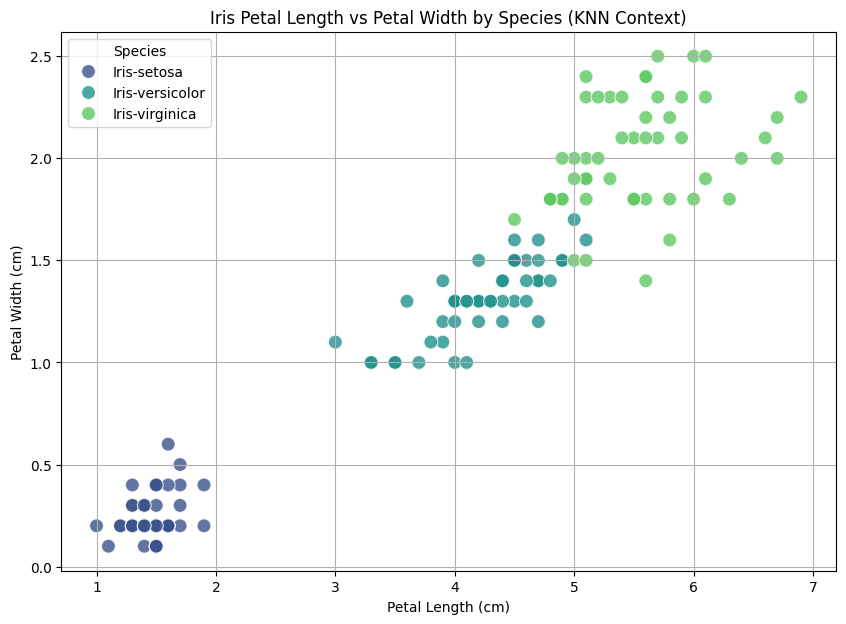

In [ ]:
print("\n--- Visualizing Iris Dataset for KNN Classification ---")
plt.figure(figsize=(10, 7))
sns.scatterplot(x='petal_length', y='petal_width', hue='species', data=df_iris, palette='viridis', s=100, alpha=0.8)
plt.title('Iris Petal Length vs Petal Width by Species (KNN Context)')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Species')
plt.grid(True)
plt.show()